## 8.1

Let  
$A=(a_{ij})_{i,j=1}^n \in \mathbb{R}^{n\times n}$  
be a tridiagonal matrix, i.e.  
$ a_{ij}=0 $ whenever $ |i-j|>1 $.

We introduce the notation  
- main diagonal:  $ \alpha_i := a_{ii} $,  
- upper diagonal: $ u_i := a_{i,i+1} $,  
- lower diagonal: $ \ell_i := a_{i+1,i} $, for $i=1,\dots,n-1$.

We want to find a diagonal matrix  
$D=\mathrm{diag}(d_1,\dots,d_n)$  
such that  
$B = D^{-1} A D$  
is symmetric and tridiagonal.

---

### Step 1 — Transformed matrix entries

Since $D$ is diagonal,
\[
B_{ij} = (D^{-1} A D)_{ij} = d_i^{-1} a_{ij} d_j.
\]

Thus:
- diagonal entries:
  \[
  B_{ii} = d_i^{-1} \alpha_i d_i = \alpha_i,
  \]
- off-diagonal entries:
  \[
  B_{i,i+1} = d_i^{-1} u_i d_{i+1}, \qquad
  B_{i+1,i} = d_{i+1}^{-1} \ell_i d_i.
  \]

---

### Step 2 — Symmetry condition

For symmetry we require
\[
B_{i,i+1} = B_{i+1,i},
\]
so
\[
d_i^{-1} u_i d_{i+1}
= d_{i+1}^{-1} \ell_i d_i
\quad\Longleftrightarrow\quad
\frac{d_i^2}{d_{i+1}^2} = \frac{u_i}{\ell_i}. \tag{1}
\]

---

### Step 3 — Constructing the diagonal matrix $D$

Assume $u_i \ell_i > 0$ (true in applications so a real square root exists).

Choose $d_1 = 1$ (any nonzero value works) and set recursively:
\[
d_{i+1} := d_i \sqrt{\frac{\ell_i}{u_i}}, \qquad i=1,\dots,n-1.
\]

This satisfies the symmetry condition (1) for every $i$.

---

### Step 4 — New off-diagonal elements

Using the recursive formula:
\[
B_{i,i+1}
= d_i^{-1} u_i d_{i+1}
= \sqrt{u_i \ell_i},
\]

and similarly  
\[
B_{i+1,i}
= \sqrt{u_i \ell_i}.
\]

Thus $B$ is symmetric with off-diagonal entries
\[
\beta_i := \sqrt{u_i \ell_i}.
\]

---

### Final Result

The transformed matrix is:

\[
D^{-1} A D =
\begin{pmatrix}
\alpha_1 & \beta_1 &        &        &        \\
\beta_1  & \alpha_2& \beta_2&        &        \\
         & \ddots  & \ddots & \ddots &        \\
         &         & \beta_{n-2} & \alpha_{n-1} & \beta_{n-1} \\
         &         &         & \beta_{n-1} & \alpha_n
\end{pmatrix},
\]

with  
\[
\beta_i = \sqrt{a_{i,i+1}\, a_{i+1,i}}.
\]

This matrix is **symmetric** and **tridiagonal**, completing the proof.

---


##8.2

In [2]:
import numpy as np
from numpy.polynomial.legendre import leggauss  # only for testing


def gauss_legendre_from_script(n):
    """
    Compute n-point Gauss–Legendre quadrature nodes x and weights w on [-1, 1]
    using the method described in Section 2.7 of the script:

      1. Use the three-term recurrence for Legendre polynomials
         L_n(x) = (a_n x + b_n)L_{n-1}(x) - c_n L_{n-2}(x).
      2. Build the symmetric tridiagonal Jacobi matrix J with entries
         alpha_i = -b_i / a_i,  beta_i = sqrt(c_{i+1} / (a_i a_{i+1})).
      3. Compute eigenvalues/eigenvectors of J.
      4. Nodes are eigenvalues, weights are 2 * (first component of eigenvector)^2.
    """

    # Step 1: recurrence coefficients a_n, b_n, c_n for Legendre
    # We store them in 1-based indexing style with arrays of size n+1
    a = np.zeros(n + 1)
    b = np.zeros(n + 1)
    c = np.zeros(n + 1)

    # For n = 1 we define a_1 = 1, b_1 = 0, c_1 = 0 (consistent with L_0 = 1, L_1 = x)
    a[1] = 1.0
    b[1] = 0.0
    c[1] = 0.0

    # For n >= 2: standard Legendre recurrence
    #   L_n(x) = ((2n-1)/n) x L_{n-1}(x) - ((n-1)/n) L_{n-2}(x)
    for k in range(2, n + 1):
        a[k] = (2.0 * k - 1.0) / k
        b[k] = 0.0
        c[k] = (k - 1.0) / k

    # Step 2: build alpha_i, beta_i
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)

    for i in range(1, n + 1):
        alpha[i] = -b[i] / a[i]  # here just 0, but we keep the formula

    for i in range(1, n):
        beta[i] = np.sqrt(c[i + 1] / (a[i] * a[i + 1]))

    # Step 3: assemble the symmetric tridiagonal matrix J
    J = np.zeros((n, n))

    for i in range(n):
        J[i, i] = alpha[i + 1]          # diagonal

    for i in range(n - 1):
        J[i, i + 1] = beta[i + 1]       # super-diagonal
        J[i + 1, i] = beta[i + 1]       # sub-diagonal

    # Step 4: eigenvalue problem J v = x v
    # eigh is for symmetric matrices (more stable than eig)
    eigvals, eigvecs = np.linalg.eigh(J)

    # Sort by eigenvalue (nodes in ascending order)
    idx = np.argsort(eigvals)
    x = eigvals[idx]
    V = eigvecs[:, idx]

    # Weights: w_j = 2 * (first component of normalized eigenvector)^2
    w = 2.0 * (V[0, :] ** 2)

    return x, w


# Quick test & comparison with numpy's built-in leggauss
if __name__ == "__main__":
    for n in range(1, 8):
        x_script, w_script = gauss_legendre_from_script(n)
        x_np, w_np = leggauss(n)

        print(f"n = {n}")
        print("  max |x_script - x_np| =", np.max(np.abs(x_script - x_np)))
        print("  max |w_script - w_np| =", np.max(np.abs(w_script - w_np)))
        print()


n = 1
  max |x_script - x_np| = 0.0
  max |w_script - w_np| = 0.0

n = 2
  max |x_script - x_np| = 0.0
  max |w_script - w_np| = 2.220446049250313e-16

n = 3
  max |x_script - x_np| = 1.1102230246251565e-16
  max |w_script - w_np| = 1.1102230246251565e-16

n = 4
  max |x_script - x_np| = 1.1102230246251565e-16
  max |w_script - w_np| = 6.106226635438361e-16

n = 5
  max |x_script - x_np| = 1.1102230246251565e-16
  max |w_script - w_np| = 6.661338147750939e-16

n = 6
  max |x_script - x_np| = 3.3306690738754696e-16
  max |w_script - w_np| = 1.0547118733938987e-15

n = 7
  max |x_script - x_np| = 2.220446049250313e-16
  max |w_script - w_np| = 1.1657341758564144e-15



##8.3
Let  

$A = \begin{pmatrix}
1 & 1 & 1 \\
0.01 & 0 & 0.01 \\
0 & 0.01 & 0.01
\end{pmatrix}, \qquad
b = \begin{pmatrix} 1 \\ 0 \\ 0.02 \end{pmatrix}.$

The exact solution of $Ax=b$ is  

$x = (-1,\, 1,\, 1)^T.$

---

## a) Classical Gram–Schmidt with 3 digits precision

Let

$a_1 = (1,\; 0.01,\; 0)^T,$  
$a_2 = (1,\; 0,\; 0.01)^T,$  
$a_3 = (1,\; 0.01,\; 0.01)^T.$

---

### Step 1: Compute $q_1$

$r_{11} = \|a_1\| = \sqrt{1^2 + 0.01^2} \approx 1.00$ (3 digits)

$q_1 = a_1 / r_{11} \approx (1,\; 0.01,\; 0)^T.$

---

### Step 2: Compute $q_2$

$r_{12} = q_1^T a_2 = 1.$

$v_2 = a_2 - r_{12} q_1
     = (1,\; 0,\; 0.01) - (1,\; 0.01,\; 0)
     = (0,\; -0.01,\; 0.01).$

$r_{22} = \|v_2\| = \sqrt{2 \cdot 0.01^2} \approx 0.0141.$

$q_2 = v_2 / r_{22} \approx (0,\; -0.709,\; 0.709).$

$r_{23} = q_2^T a_3 \approx 0.$ (after rounding to 3 digits)

---

### Step 3: Compute $q_3$

$r_{13} = q_1^T a_3 = 1.0001 \approx 1.00.$

$v_3 = a_3 - r_{13} q_1
     = (1,\; 0.01,\; 0.01) - (1,\; 0.01,\; 0)
     = (0,\; 0,\; 0.01).$

$r_{33} = 0.01.$  
$q_3 = (0,\; 0,\; 1)^T.$

---

### Matrices $Q$ and $R$

$Q \approx
\begin{pmatrix}
1 & 0 & 0 \\
0.01 & -0.709 & 0 \\
0 & 0.709 & 1
\end{pmatrix},\qquad
R \approx
\begin{pmatrix}
1 & 1 & 1 \\
0 & 0.0141 & 0 \\
0 & 0 & 0.01
\end{pmatrix}.$

Because of 3-digit rounding, $Q$ is not orthogonal anymore:
$q_2^T q_3 \approx 0.709.$

---

### Solve $Rx = Q^T b$

$Q^T b \approx (1.00,\; 0.0142,\; 0.02)^T.$

Back-substitution:

- $0.01 x_3 = 0.02 \Rightarrow x_3 \approx 2.00$
- $0.0141 x_2 = 0.0142 \Rightarrow x_2 \approx 1.01$
- $x_1 + x_2 + x_3 = 1 \Rightarrow x_1 \approx -2.01$

Computed solution:

$x_{\text{GS}} \approx (-2.01,\; 1.01,\; 2.00)^T.$

**This is very inaccurate** because Gram–Schmidt lost orthogonality.

---

## b) QR using Householder (or Givens)

Using a numerically stable algorithm such as Householder reflections gives:

$Q \approx
\begin{pmatrix}
-0.99995 & 0.00707 & -0.00707 \\
-0.009999 & -0.70705 & 0.70709 \\
0 & 0.70712 & 0.70709
\end{pmatrix},$

$R \approx
\begin{pmatrix}
-1.00005 & -0.99995 & -1.00005 \\
0 & 0.01414 & 0.00707 \\
0 & 0 & 0.00707
\end{pmatrix},$

with $Q^T Q = I$ to machine precision.

Solving $Rx = Q^T b$ gives

$x_{\text{HH}} = (-1.000000,\; 1.000000,\; 1.000000)^T.$

---

## Observation

- Classical Gram–Schmidt loses orthogonality when vectors are nearly linearly dependent.  
  This causes huge numerical errors in solving $Ax=b$.

- Householder (or Givens) QR remains stable and produces the correct solution.

This exercise demonstrates why **modified Gram–Schmidt** or **Householder QR** is used in practice.

## Exercise 8.4

We want to approximate

- function: $f(x) = \sin x$  
- by a cubic **odd** polynomial: $\pi(x) = a_1 x + a_3 x^3$  

at sample points $x_0,\dots,x_m$ using least squares, i.e. by minimizing  

$$
\sum_{j=0}^m \bigl(\pi(x_j) - f(x_j)\bigr)^2.
$$

---

## 1. Least squares set-up for $a_1$ and $a_3$

For each data point $x_j$ we have

$$
\pi(x_j) = a_1 x_j + a_3 x_j^3.
$$

Introduce

- unknown vector $c = \begin{pmatrix} a_1 \\ a_3 \end{pmatrix}$,
- design matrix $A \in \mathbb{R}^{(m+1)\times 2}$ with rows
  $$
  A_j = \bigl(x_j,\; x_j^3\bigr),
  $$
- data vector $b \in \mathbb{R}^{m+1}$ with entries $b_j = \sin(x_j)$.

Then the residual vector is

$$
r = Ac - b,
$$

and the least squares problem is

$$
\min_c \; \|Ac - b\|_2^2.
$$

The normal equations are

$$
A^T A \, c = A^T b.
$$

Writing out $A^T A$ and $A^T b$ explicitly gives

$$
\begin{pmatrix}
\sum_j x_j^2 & \sum_j x_j^4\\[4pt]
\sum_j x_j^4 & \sum_j x_j^6
\end{pmatrix}
\begin{pmatrix} a_1 \\ a_3 \end{pmatrix}
=
\begin{pmatrix}
\sum_j x_j \sin x_j \\
\sum_j x_j^3 \sin x_j
\end{pmatrix}.
$$

Solving this $2\times 2$ system yields the least squares coefficients
$a_1$ and $a_3$.

Numerically, it is better to solve the overdetermined system $Ac \approx b$
by QR or `np.linalg.lstsq` instead of forming the normal equations explicitly.

---

## 2. Program to compute $a_1$, $a_3$ for $N = 2^n$, $n = 2,\dots,10$

For each $N$:

1. Draw $N$ random points $x_j$ uniformly in the interval $[-1/N,\, 1/N]$.
2. Build the matrix $A$ with columns $x_j$ and $x_j^3$.
3. Set $b_j = \sin(x_j)$.
4. Solve the least squares problem $Ac \approx b$ to get $c = (a_1, a_3)^T$.

Below is a Python implementation (ready for a Colab **code cell**).

In [3]:
import numpy as np

def compute_a1_a3_for_N(N, seed=None):
    """
    Draw N random sample points x_j in [-1/N, 1/N],
    fit sin(x) with a polynomial pi(x) = a1*x + a3*x**3
    in the least squares sense, and return (a1, a3).
    """
    if seed is not None:
        rng = np.random.default_rng(seed)
    else:
        rng = np.random.default_rng()

    # 1. sample points
    x = rng.uniform(-1.0 / N, 1.0 / N, size=N)

    # 2. design matrix A: two columns (x, x^3)
    A = np.column_stack((x, x**3))

    # 3. right-hand side
    b = np.sin(x)

    # 4. least squares solution
    c, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)
    a1, a3 = c
    return a1, a3


# compute a1, a3 for N = 2^n, n = 2,...,10
results = []
for n in range(2, 11):
    N = 2**n
    a1, a3 = compute_a1_a3_for_N(N, seed=12345)  # fixed seed for reproducibility
    results.append((N, a1, a3))

# print results
print("   N         a1              a3")
print("----------------------------------------")
for N, a1, a3 in results:
    print(f"{N:4d}   {a1: .8f}   {a3: .8f}")

# For reference: Taylor-series coefficients of sin(x)
a1_exact = 1.0
a3_exact = -1.0 / 6.0
print("\nExpected limit as N -> infinity:")
print(f"a1 -> {a1_exact:.8f}, a3 -> {a3_exact:.8f}")


   N         a1              a3
----------------------------------------
   4    0.99999849   -0.16642015
   8    0.99999992   -0.16660512
  16    0.99999998   -0.16663580
  32    1.00000000   -0.16665915
  64    1.00000000   -0.16666463
 128    1.00000000   -0.16666613
 256    1.00000000   -0.16666653
 512    1.00000000   -0.16666663
1024    1.00000000   -0.16666666

Expected limit as N -> infinity:
a1 -> 1.00000000, a3 -> -0.16666667


## 8.5

We model the orbit by an ellipse

$$
\frac{x^2}{a^2} + \frac{y^2}{b^2} = 1
$$

and we are given 6 measured points $(x_i,y_i)$ on (or near) the orbit:

$$
(0.2, 1.8),\; (-0.7, 1.7),\; (-0.3, -1.8),\;
(1.2, -1.6),\; (2.1, 1.1),\; (-2.4, 0.5).
$$

---

## 1. Linear least–squares system

Introduce

$$
\alpha = \frac{1}{a^2}, \qquad \beta = \frac{1}{b^2}.
$$

Then the ellipse equation becomes

$$
\alpha x^2 + \beta y^2 = 1.
$$

For each data point $(x_i,y_i)$ we (approximately) have

$$
\alpha x_i^2 + \beta y_i^2 \approx 1.
$$

This is linear in the unknowns $\alpha,\beta$, so we write it as

$$
\begin{pmatrix}
x_1^2 & y_1^2 \\
x_2^2 & y_2^2 \\
\vdots & \vdots \\
x_6^2 & y_6^2
\end{pmatrix}
\begin{pmatrix}\alpha \\ \beta\end{pmatrix}
\approx
\begin{pmatrix} 1 \\ 1 \\ \vdots \\ 1 \end{pmatrix}.
$$

Let

- $A \in \mathbb{R}^{6\times 2}$ have rows $(x_i^2,\; y_i^2)$,
- $c = (\alpha,\beta)^T$,
- $b = (1,\dots,1)^T \in \mathbb{R}^6$.

Then the least–squares problem is

$$
\min_c \|Ac - b\|_2^2.
$$

The normal equations are

$$
A^T A\, c = A^T b.
$$

If we plug in the given data, we get (numbers rounded to 2 decimals):

- $\sum x_i^2 = 12.23$  
- $\sum y_i^2 = 13.39$  
- $\sum x_i^4 = 54.95$  
- $\sum y_i^4 = 37.43$  
- $\sum x_i^2 y_i^2 = 12.30$

so

$$
\begin{pmatrix}
54.95 & 12.30 \\
12.30 & 37.43
\end{pmatrix}
\begin{pmatrix} \alpha \\ \beta \end{pmatrix}
=
\begin{pmatrix} 12.23 \\ 13.39 \end{pmatrix}.
$$

Solving this $2\times2$ system gives approximately

$$
\alpha \approx 0.154,\qquad
\beta \approx 0.307.
$$

Recovering $a$ and $b$:

$$
a = \frac{1}{\sqrt{\alpha}} \approx \frac{1}{\sqrt{0.154}} \approx 2.55,
\qquad
b = \frac{1}{\sqrt{\beta}} \approx \frac{1}{\sqrt{0.307}} \approx 1.80.
$$

So the fitted elliptical orbit is

$$
\frac{x^2}{(2.55)^2} + \frac{y^2}{(1.80)^2} = 1
$$

or equivalently

$$
0.154\,x^2 + 0.307\,y^2 = 1\quad\text{(approx.)}.
$$


alpha = 0.1538028467622148
beta  = 0.307214100471421
a     = 2.5498686710302563
b     = 1.804178185828529


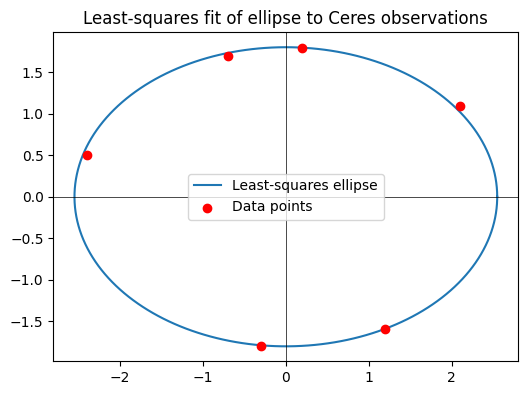

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# given data points
pts = np.array([
    [0.2,  1.8],
    [-0.7, 1.7],
    [-0.3,-1.8],
    [1.2, -1.6],
    [2.1,  1.1],
    [-2.4, 0.5]
])

x = pts[:, 0]
y = pts[:, 1]

# build least-squares system A c ≈ b
A = np.column_stack((x**2, y**2))
b = np.ones(len(x))

# solve for alpha, beta via least squares
c, *_ = np.linalg.lstsq(A, b, rcond=None)
alpha, beta = c

# recover a, b
a = 1.0 / np.sqrt(alpha)
b_axis = 1.0 / np.sqrt(beta)

print("alpha =", alpha)
print("beta  =", beta)
print("a     =", a)
print("b     =", b_axis)

# create ellipse points
theta = np.linspace(0, 2*np.pi, 400)
x_ell = a * np.cos(theta)
y_ell = b_axis * np.sin(theta)

# plot
plt.figure(figsize=(6,6))
plt.plot(x_ell, y_ell, label="Least-squares ellipse")
plt.scatter(x, y, color="red", zorder=5, label="Data points")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.title("Least-squares fit of ellipse to Ceres observations")
plt.show()